# Fase 2
## Carga del dataset

En esta etapa se revisará que el dataset, formato, estructura. Este dataset es consultado de Kaggle.
La importancia de la revisión nos dirá si el dataset sirve para el poder desarrollar el proyecto.

In [1]:
import pandas as pd
import numpy as np
df = pd.read_csv('telco_customer_data_v2.csv')
print(df.shape)
print(df.dtypes)
print(df.head(3))

(70000, 21)
customerID           object
gender               object
SeniorCitizen        object
Partner              object
Dependents           object
tenure              float64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object
  customerID  gender SeniorCitizen Partner Dependents  tenure PhoneService  \
0  CUST00001    Male             0      No        Yes     3.0          Yes   
1  CUST00002    Male             1     Yes         No     2.0          Yes   
2  CUST00003  Female            No      No         No    42.0          Yes   

  MultipleLines InternetService       OnlineSecurity  ...  \
0           

# Fase 3 Limpieza

El primer paso es revisar que el dataset, no sólo tenga datos sino que la tenga consistencia en ellos, es decir, que los datos estén en formatos adecuado para la información que representan. Que no almacene valores duplicados, nulos o inconsistencias en la escritura de los mismos.

In [2]:
print(f"El número de filas duplicadas en el df es de: {df.duplicated().sum()}")
print(f'Las columnas con valores nulos son:\n{df.isnull().sum()[df.isnull().sum()>0]}')
print(f'Lo cual representa el porcentaje de:\n{(df.isnull().mean()*100)[lambda x:x > 0]}')


El número de filas duplicadas en el df es de: 0
Las columnas con valores nulos son:
gender               748
SeniorCitizen        659
Partner             3530
Dependents          3565
tenure               567
MultipleLines       1868
OnlineSecurity      2922
OnlineBackup        2747
DeviceProtection    2894
TechSupport         2733
StreamingTV         2827
StreamingMovies     2785
PaymentMethod       3569
MonthlyCharges       388
TotalCharges        1062
dtype: int64
Lo cual representa el porcentaje de:
gender              1.068571
SeniorCitizen       0.941429
Partner             5.042857
Dependents          5.092857
tenure              0.810000
MultipleLines       2.668571
OnlineSecurity      4.174286
OnlineBackup        3.924286
DeviceProtection    4.134286
TechSupport         3.904286
StreamingTV         4.038571
StreamingMovies     3.978571
PaymentMethod       5.098571
MonthlyCharges      0.554286
TotalCharges        1.517143
dtype: float64


In [3]:
df[['tenure','MonthlyCharges']].describe()


,tenure,MonthlyCharges
count,69433.000000,69612.000000
mean,30.516858,60.588548
std,89.873767,111.509588
min,-10.000000,18.000000
25%,10.000000,29.670000
50%,20.000000,41.190000
75%,35.000000,63.882500
max,999.000000,1499.770000


## Hallazgos en inspección de datos
Nulos:
Se han encontrado varias columnas que llegan a tener hasta un 5% de valores nulos, hay que revisar, a qué se debe y cómo abordar esa situación.

Duplicados: 0 filas duplicadas exactas.

Numéricas (tenure, MonthlyCharges):
En la columna tenure es imposible tener un registro negativo y el máx, tampoco está bien registrado. De igual manera la columna MonthlyCharges tiene datos mal registrado que deberán ser evaluados.

TotalCharges como object:
está como object porque contiene valores con formato mixto, por ejemplo "170.781, USD": separador decimal por coma, sufijo de moneda, y posible separador de miles. Requiere parseo customizado antes de convertir a numérico.



In [4]:
#Target Churn → binario. (Limpieza)

df['Churn'] = df['Churn'].replace('CHURNED', 'Yes')
df['Churn'] = df['Churn'].replace('N', 'No')
df['Churn'] = df['Churn'].replace('NO CHURN', 'No')
df['Churn'] = df['Churn'].replace('Y', 'Yes')
df['Churn'].value_counts()

,count
Churn,
No,37148
Yes,32798
Unknown,54


In [5]:
#SeniorCitizen → binario. (Limpieza)

df['SeniorCitizen'] = df['SeniorCitizen'].replace('0','No')
df['SeniorCitizen'] = df['SeniorCitizen'].replace('1','Yes')
df['SeniorCitizen'] = df['SeniorCitizen'].replace('not senior','No')
df['SeniorCitizen'].value_counts()

,count
SeniorCitizen,
No,55394
Yes,13947


#Numéricas: tenure, MonthlyCharges, TotalCharges. (Limpieza)

TotalCharges.
Tiene varios problemas ya que varios registros tienen el signo de dolares, coma, la moneda o punto y en diferentes Posiciones

In [6]:

df['TotalCharges'] = (df['TotalCharges'].astype(str).str.replace(r'USD|dollars|\$|','',regex=True).str.strip())
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(f'El formato actual de la columna es: {df['TotalCharges'].dtype}')
print(f'El número total de valores vacíos en la columna es: {df['TotalCharges'].isna().sum()}')
print(df['TotalCharges'].describe())
#Hay que ver cuántos valores negativos hay
print(f'El número de valores negativos es:{(df['TotalCharges'] < 0).sum()}')
print(f'Los valores más altos son:{df['TotalCharges'].nlargest(5)}')

El formato actual de la columna es: float64
El número total de valores vacíos en la columna es: 2023
count    6.797700e+04
mean     1.806892e+03
std      9.673285e+03
min     -9.912000e+01
25%      3.802000e+02
50%      8.220000e+02
75%      1.540140e+03
max      1.244434e+06
Name: TotalCharges, dtype: float64
El número de valores negativos es:198
Los valores más altos son:1140     1244434.32
53134    1009789.20
5357      861467.67
66276     677082.24
54695     574415.01
Name: TotalCharges, dtype: float64


Como se puede observar hay valores que son imposibles ya que revasan la logica de negocio.
Por el momento se informa sobre esta situación

In [7]:
#Revision de tenure y MonthlyCharges
print(f'El número de registro vacíos o nulos en la columna "tenure" son: {df['tenure'].isnull().sum() or df['tenure'].isna().sum()}')
print(df['tenure'].describe())
print(f'El número de registro vacíos o nulos en la columna "MonthlyCharges" son: {df['MonthlyCharges'].isnull().sum() or df['MonthlyCharges'].isna().sum()}')
print(df['MonthlyCharges'].describe())


El número de registro vacíos o nulos en la columna "tenure" son: 567
count    69433.000000
mean        30.516858
std         89.873767
min        -10.000000
25%         10.000000
50%         20.000000
75%         35.000000
max        999.000000
Name: tenure, dtype: float64
El número de registro vacíos o nulos en la columna "MonthlyCharges" son: 388
count    69612.000000
mean        60.588548
std        111.509588
min         18.000000
25%         29.670000
50%         41.190000
75%         63.882500
max       1499.770000
Name: MonthlyCharges, dtype: float64


Se observa que hay valores nulos, estos se dejarán así, ya que en ambas columnas no representan un porcentaje mayor.

Sin embargo, en ambas columnas se ha encontrado una inconsistencia en ls distribución de los datos, ya que hay valores atipicos y negativos. Se definieron los siguientes limites para las columnas

* Tenure de 0 -72
* MonthlyCharges 18 - 300 Dolares

In [8]:
#Convertir en Nan aquellos datos que estén fuera de los rangos
df.loc[(df['tenure']) < 0 | (df['tenure']> 72), 'tenure'] = np.nan


df.loc[(df['MonthlyCharges']<18)|(df['MonthlyCharges']>200), 'MonthlyCharges'] = np.nan

df.loc[(df['TotalCharges']<0)|(df['TotalCharges']>14400),'TotalCharges'] = np.nan

In [9]:
num_cols = df.select_dtypes(include=['int64','float']).columns.tolist()
cat_cols = df.select_dtypes(include=['object']).columns.tolist()

print(num_cols)
print(cat_cols)

['tenure', 'MonthlyCharges', 'TotalCharges']
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']


In [10]:
#Categóricas: unificar valores. (Limpieza)
for cat in cat_cols:
  if cat == 'customerID':
    continue
  else:
    print(f'Los valores únicos de la columna: {cat} son:\n{df[cat].value_counts()}')


Los valores únicos de la columna: gender son:
gender
Female    34110
Male      33252
Man         500
male        374
FEMALE      351
m           339
f           326
Name: count, dtype: int64
Los valores únicos de la columna: SeniorCitizen son:
SeniorCitizen
No     55394
Yes    13947
Name: count, dtype: int64
Los valores únicos de la columna: Partner son:
Partner
No     38344
Yes    28126
Name: count, dtype: int64
Los valores únicos de la columna: Dependents son:
Dependents
No     45375
Yes    21060
Name: count, dtype: int64
Los valores únicos de la columna: PhoneService son:
PhoneService
Yes    63011
No      6989
Name: count, dtype: int64
Los valores únicos de la columna: MultipleLines son:
MultipleLines
Yes                 34681
No                  25192
No phone service     8259
Name: count, dtype: int64
Los valores únicos de la columna: InternetService son:
InternetService
Fiber optic    38502
DSL            17594
No             13904
Name: count, dtype: int64
Los valores únicos de 

In [11]:
#Genero
df['gender'] = df['gender'].replace('Man','Male')
df['gender'] = df['gender'].replace('male','Male')
df['gender'] = df['gender'].replace('FEMALE','Female')
df['gender'] = df['gender'].replace('m','Male')
df['gender'] = df['gender'].replace('f','Female')

# MultipleLines
df['MultipleLines'] = df['MultipleLines'].replace('No phone service ','No')

#OnlineSecurity
df['OnlineSecurity'] = df['OnlineSecurity'].replace('True','Yes')
df['OnlineSecurity'] = df['OnlineSecurity'].replace('Y','Yes')

#OnlineBackup
df['OnlineBackup'] = df['OnlineBackup'].replace('Y','Yes')
df['OnlineBackup'] = df['OnlineBackup'].replace('True','Yes')

#DeviceProtection
df['DeviceProtection'] = df['DeviceProtection'].replace('Y','Yes')
df['DeviceProtection'] = df['DeviceProtection'].replace('True','Yes')

#TechSupport
df['TechSupport'] = df['TechSupport'].replace('Y','Yes')
df['TechSupport'] = df['TechSupport'].replace('True','Yes')

#StreamingTV
df['StreamingTV'] = df['StreamingTV'].replace('Y','Yes')
df['StreamingTV'] = df['StreamingTV'].replace('True','Yes')

#StreamingMovies
df['StreamingMovies'] = df['StreamingMovies'].replace('Y','Yes')
df['StreamingMovies'] = df['StreamingMovies'].replace('True','Yes')

#Contract
df['Contract'] = df['Contract'].replace('M-M','Month-to-month')

#PaymentMethod
df['PaymentMethod'] = df['PaymentMethod'].replace('Bank transfer (automatic)','BANK TRANSFER')

#InternetService
df['InternetService'] = df['InternetService'].replace('Fi','Fiber optic')


for cat in cat_cols:
  if cat == 'customerID':
    continue
  else:
    print(f'Los valores únicos de la columna: {cat} son:\n{df[cat].value_counts()}')


Los valores únicos de la columna: gender son:
gender
Female    34787
Male      34465
Name: count, dtype: int64
Los valores únicos de la columna: SeniorCitizen son:
SeniorCitizen
No     55394
Yes    13947
Name: count, dtype: int64
Los valores únicos de la columna: Partner son:
Partner
No     38344
Yes    28126
Name: count, dtype: int64
Los valores únicos de la columna: Dependents son:
Dependents
No     45375
Yes    21060
Name: count, dtype: int64
Los valores únicos de la columna: PhoneService son:
PhoneService
Yes    63011
No      6989
Name: count, dtype: int64
Los valores únicos de la columna: MultipleLines son:
MultipleLines
Yes                 34681
No                  25192
No phone service     8259
Name: count, dtype: int64
Los valores únicos de la columna: InternetService son:
InternetService
Fiber optic    38502
DSL            17594
No             13904
Name: count, dtype: int64
Los valores únicos de la columna: OnlineSecurity son:
OnlineSecurity
No                     39195
No i

In [12]:
#Nulos: estrategia por columna. (Limpieza)



In [13]:
#Duplicados: cerrar con evidencia. (Limpieza)
print(df['customerID'].duplicated())

0        False
1        False
2        False
3        False
4        False
         ...  
69995    False
69996    False
69997    False
69998    False
69999    False
Name: customerID, Length: 70000, dtype: bool


## Fase 4
EDA

Pasos:

* **Análisis univariado de variables numéricas**: Evaluar las distribuciones reales, sesgos y dispersión de `tenure`, `MonthlyCharges` y `TotalCharges` manteniendo los `NaN` actuales para no distorsionar la estadística descriptiva.

* **Análisis univariado de variables categóricas**: Calcular tablas de frecuencia y proporciones de las categorías normalizadas para entender la composición del dataset.

* **Inspección de la variable objetivo (`Churn`)**: Cuantificar la proporción de bajas frente a clientes retenidos para identificar el nivel de desbalance de clases.

* **Análisis bivariado (Variables predictoras vs. `Churn`)**: Cruzar las variables numéricas y categóricas con el estado de cancelación para detectar patrones visuales y tendencias de fuga de clientes.

* **Matriz de correlación**: Analizar la relación lineal entre variables numéricas y descartar posibles problemas de multicolinealidad.

* **Definición de la estrategia de imputación (Cierre de limpieza)**: Con base en los hallazgos del EDA, decidir el método definitivo para rellenar los valores `NaN` creados en la Fase 3 antes de pasar al modelado.


La media de la columna tenure es:31.16399349650657
La mediana de la columna tenure es:21.0
La desviación estandar de la columna tenure es:90.49665381802637
El valor minimo de la columna tenure es:1.0
El valor máximo de la columna tenure es:999.0
El Cuartil 25 de la columna tenure es:10.0
El Cuartil 50 de la columna tenure es:21.0
El Cuartil 75 de la columna tenure es:35.0
El número de valores faltantes en la columna tenure es 1729 lo que equivale a 2.47% de la columna


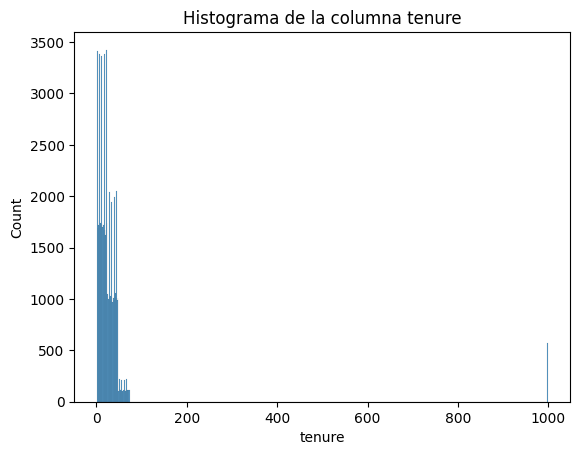

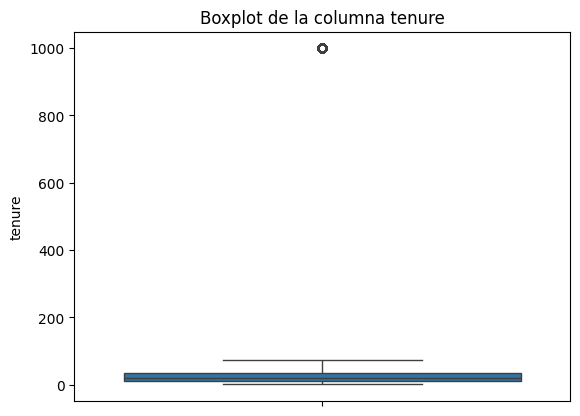

La media de la columna MonthlyCharges es:49.04939073521925
La mediana de la columna MonthlyCharges es:40.89
La desviación estandar de la columna MonthlyCharges es:26.41315406098686
El valor minimo de la columna MonthlyCharges es:18.0
El valor máximo de la columna MonthlyCharges es:118.0
El Cuartil 25 de la columna MonthlyCharges es:29.52
El Cuartil 50 de la columna MonthlyCharges es:40.89
El Cuartil 75 de la columna MonthlyCharges es:61.855000000000004
El número de valores faltantes en la columna MonthlyCharges es 1245 lo que equivale a 1.78% de la columna


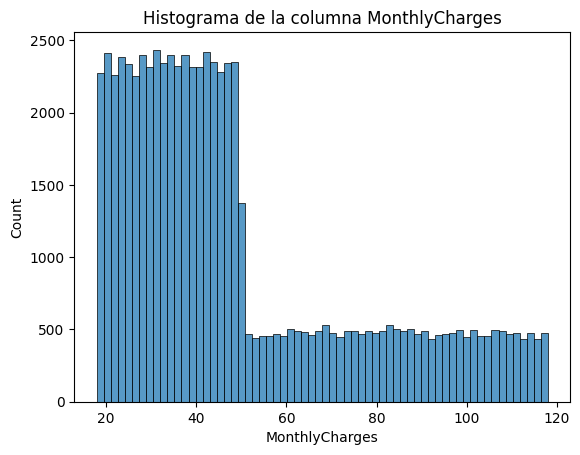

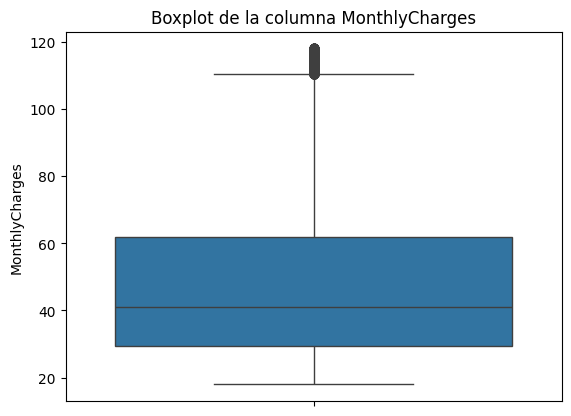

La media de la columna TotalCharges es:1133.5203352918256
La mediana de la columna TotalCharges es:809.045
La desviación estandar de la columna TotalCharges es:1166.1939874646173
El valor minimo de la columna TotalCharges es:0.0
El valor máximo de la columna TotalCharges es:14398.74
El Cuartil 25 de la columna TotalCharges es:377.4
El Cuartil 50 de la columna TotalCharges es:809.045
El Cuartil 75 de la columna TotalCharges es:1495.8
El número de valores faltantes en la columna TotalCharges es 3282 lo que equivale a 4.69% de la columna


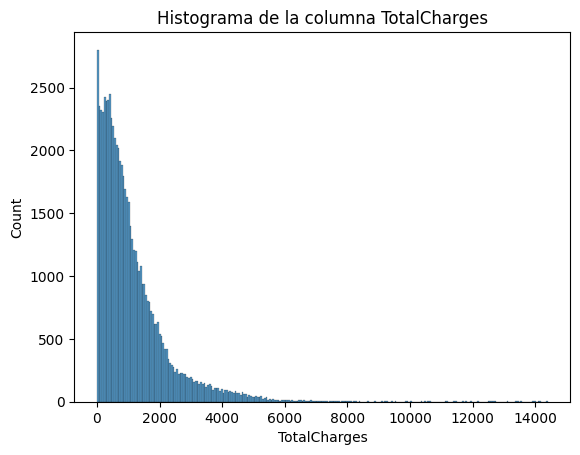

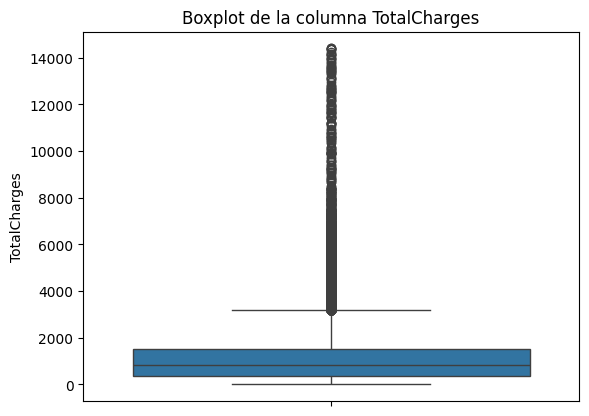

In [14]:
#Análisis univariado de variables numéricas
import seaborn as sns
import matplotlib.pyplot as plt


for col in num_cols:
  print(f'La media de la columna {col} es:{df[col].mean()}')
  print(f'La mediana de la columna {col} es:{df[col].median()}')
  print(f'La desviación estandar de la columna {col} es:{df[col].std()}')
  print(f'El valor minimo de la columna {col} es:{df[col].min()}')
  print(f'El valor máximo de la columna {col} es:{df[col].max()}')
  print(f'El Cuartil 25 de la columna {col} es:{df[col].quantile(0.25)}')
  print(f'El Cuartil 50 de la columna {col} es:{df[col].quantile(0.50)}')
  print(f'El Cuartil 75 de la columna {col} es:{df[col].quantile(0.75)}')
  print(f'El número de valores faltantes en la columna {col} es {df[col].isna().sum()} lo que equivale a {(df[col].isna().sum()/ len(df)) *100:.2f}% de la columna')
  sns.histplot(data=df, x= col)
  plt.title(f"Histograma de la columna {col}")
  plt.show()
  sns.boxplot(y=col, data=df)
  plt.title(f"Boxplot de la columna {col}")
  plt.show()

La frecuencia de los valores de esta columna son: gender
Female    34787
Male      34465
Name: count, dtype: int64
Y su porcentaje equivale a gender
Female    50.232484
Male      49.767516
Name: proportion, dtype: float64%


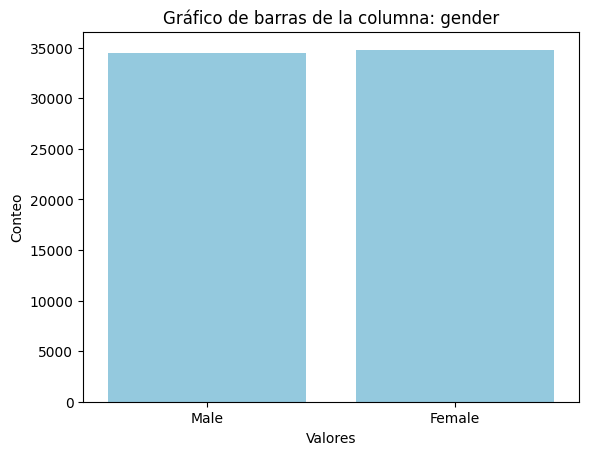

La frecuencia de los valores de esta columna son: SeniorCitizen
No     55394
Yes    13947
Name: count, dtype: int64
Y su porcentaje equivale a SeniorCitizen
No     79.886359
Yes    20.113641
Name: proportion, dtype: float64%


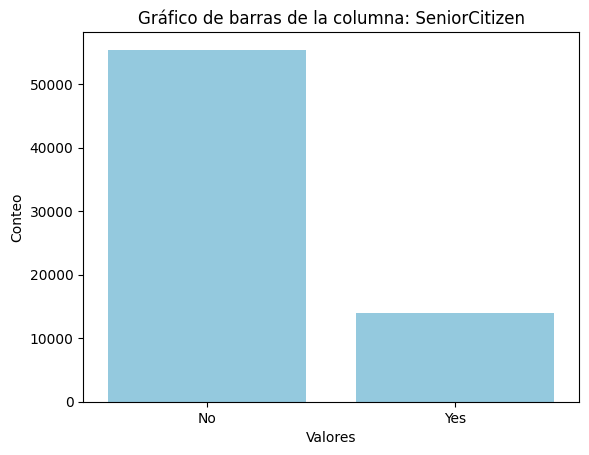

La frecuencia de los valores de esta columna son: Partner
No     38344
Yes    28126
Name: count, dtype: int64
Y su porcentaje equivale a Partner
No     57.686174
Yes    42.313826
Name: proportion, dtype: float64%


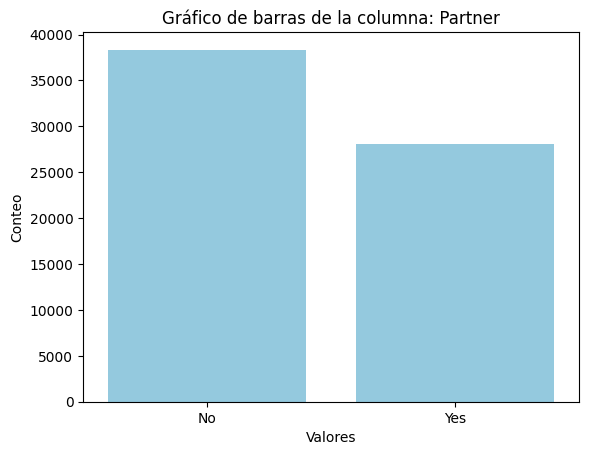

La frecuencia de los valores de esta columna son: Dependents
No     45375
Yes    21060
Name: count, dtype: int64
Y su porcentaje equivale a Dependents
No     68.299842
Yes    31.700158
Name: proportion, dtype: float64%


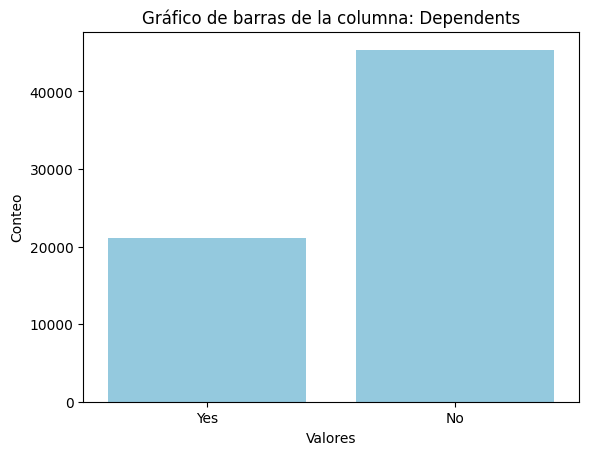

La frecuencia de los valores de esta columna son: PhoneService
Yes    63011
No      6989
Name: count, dtype: int64
Y su porcentaje equivale a PhoneService
Yes    90.015714
No      9.984286
Name: proportion, dtype: float64%


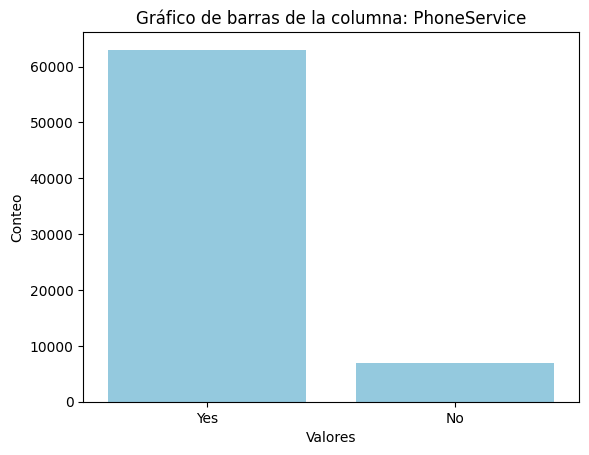

La frecuencia de los valores de esta columna son: MultipleLines
Yes                 34681
No                  25192
No phone service     8259
Name: count, dtype: int64
Y su porcentaje equivale a MultipleLines
Yes                 50.902660
No                  36.975283
No phone service    12.122057
Name: proportion, dtype: float64%


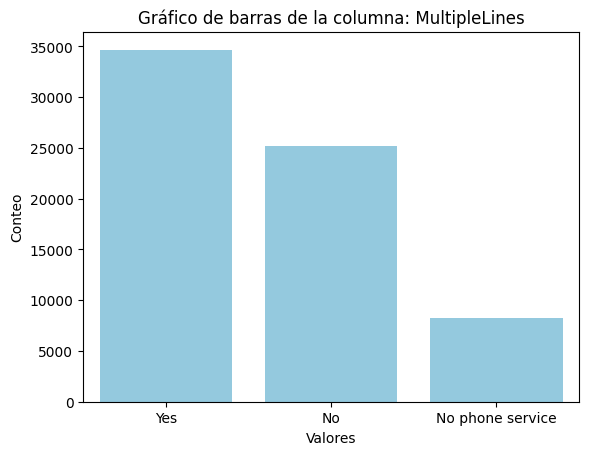

La frecuencia de los valores de esta columna son: InternetService
Fiber optic    38502
DSL            17594
No             13904
Name: count, dtype: int64
Y su porcentaje equivale a InternetService
Fiber optic    55.002857
DSL            25.134286
No             19.862857
Name: proportion, dtype: float64%


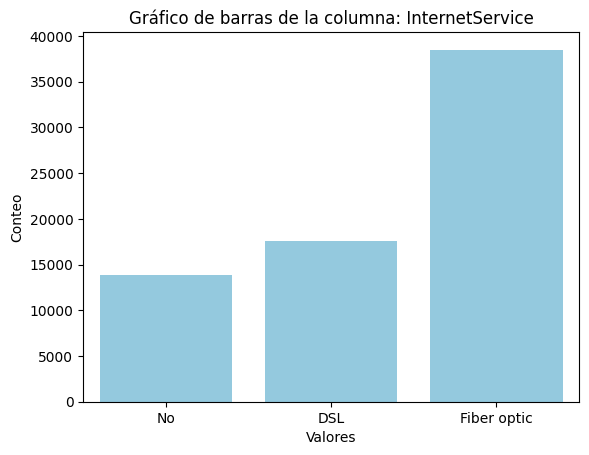

La frecuencia de los valores de esta columna son: OnlineSecurity
No                     39195
No internet service    16672
Yes                    11211
Name: count, dtype: int64
Y su porcentaje equivale a OnlineSecurity
No                     58.431975
No internet service    24.854647
Yes                    16.713378
Name: proportion, dtype: float64%


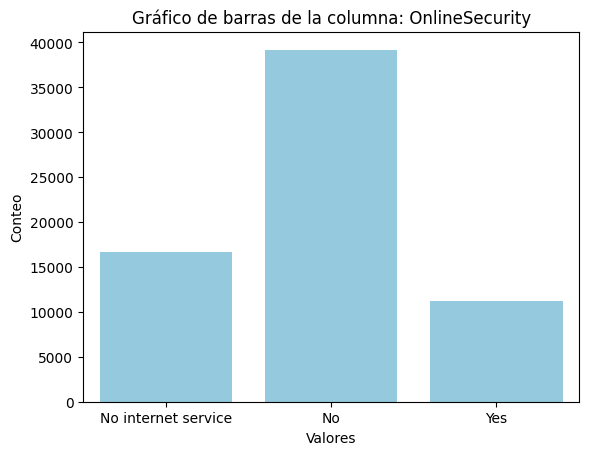

La frecuencia de los valores de esta columna son: OnlineBackup
No                     39308
No internet service    16691
Yes                    11254
Name: count, dtype: int64
Y su porcentaje equivale a OnlineBackup
No                     58.447950
No internet service    24.818224
Yes                    16.733826
Name: proportion, dtype: float64%


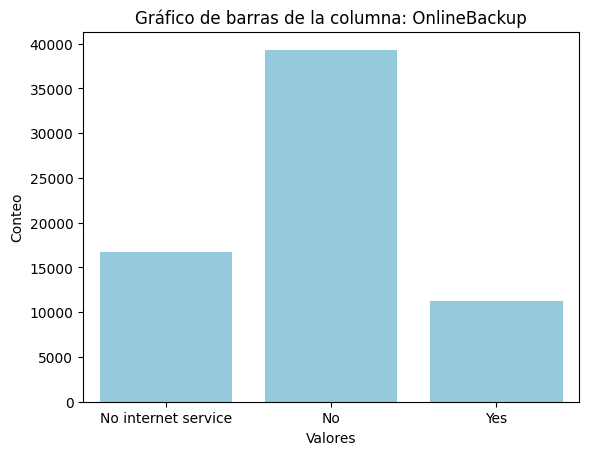

La frecuencia de los valores de esta columna son: DeviceProtection
No                     39199
No internet service    16623
Yes                    11284
Name: count, dtype: int64
Y su porcentaje equivale a DeviceProtection
No                     58.413555
No internet service    24.771257
Yes                    16.815188
Name: proportion, dtype: float64%


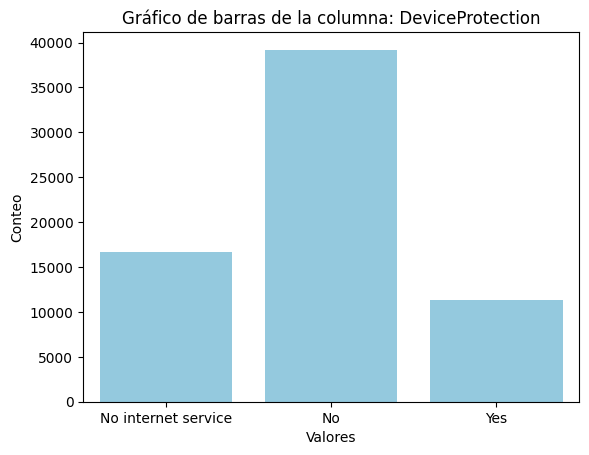

La frecuencia de los valores de esta columna son: TechSupport
No                     39401
No internet service    16616
Yes                    11250
Name: count, dtype: int64
Y su porcentaje equivale a TechSupport
No                     58.574041
No internet service    24.701562
Yes                    16.724397
Name: proportion, dtype: float64%


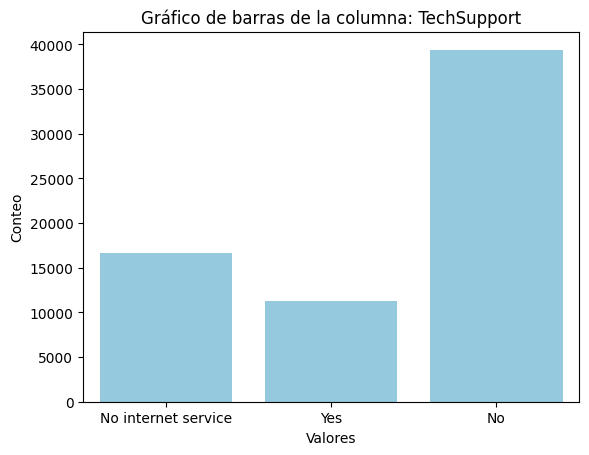

La frecuencia de los valores de esta columna son: StreamingTV
No                     39198
No internet service    16610
Yes                    11365
Name: count, dtype: int64
Y su porcentaje equivale a StreamingTV
No                     58.353803
No internet service    24.727197
Yes                    16.919000
Name: proportion, dtype: float64%


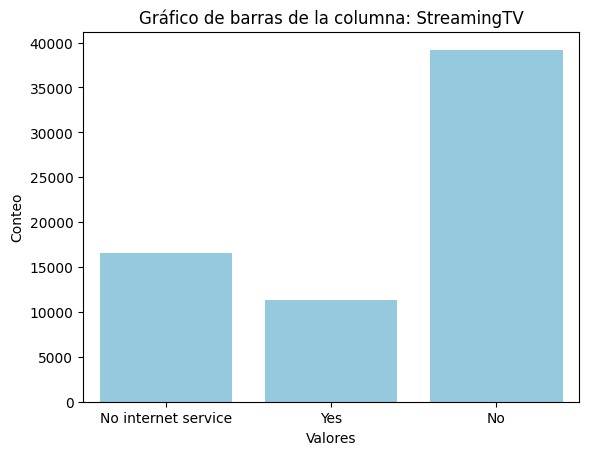

La frecuencia de los valores de esta columna son: StreamingMovies
No                     39189
No internet service    16744
Yes                    11282
Name: count, dtype: int64
Y su porcentaje equivale a StreamingMovies
No                     58.303950
No internet service    24.911106
Yes                    16.784944
Name: proportion, dtype: float64%


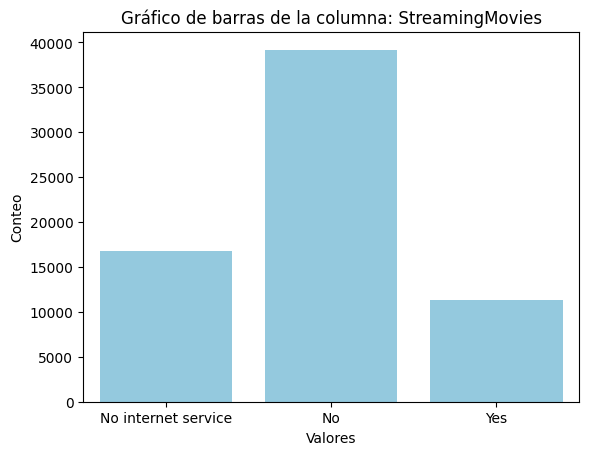

La frecuencia de los valores de esta columna son: Contract
Month-to-month    42011
One year          14015
Two year          13974
Name: count, dtype: int64
Y su porcentaje equivale a Contract
Month-to-month    60.015714
One year          20.021429
Two year          19.962857
Name: proportion, dtype: float64%


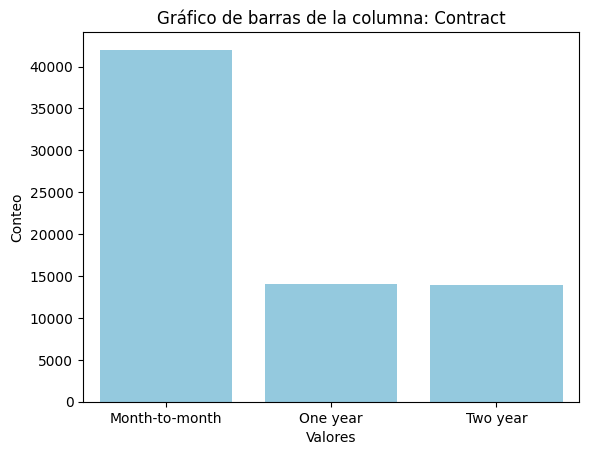

La frecuencia de los valores de esta columna son: PaperlessBilling
Yes    42011
No     27989
Name: count, dtype: int64
Y su porcentaje equivale a PaperlessBilling
Yes    60.015714
No     39.984286
Name: proportion, dtype: float64%


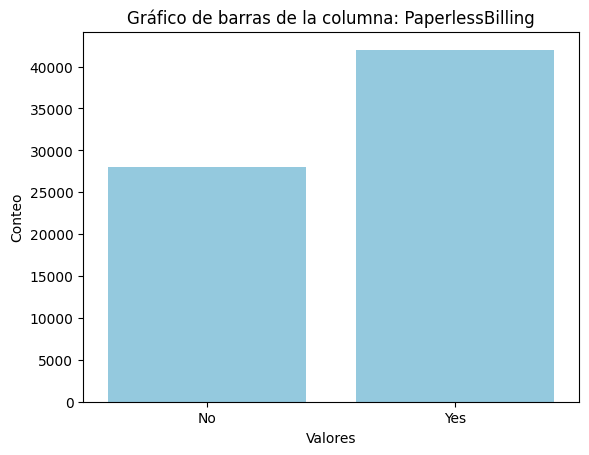

La frecuencia de los valores de esta columna son: PaymentMethod
Electronic check           27841
BANK TRANSFER              14227
Mailed check               13963
Credit card (automatic)    10400
Name: count, dtype: int64
Y su porcentaje equivale a PaymentMethod
Electronic check           41.909651
BANK TRANSFER              21.416206
Mailed check               21.018801
Credit card (automatic)    15.655342
Name: proportion, dtype: float64%


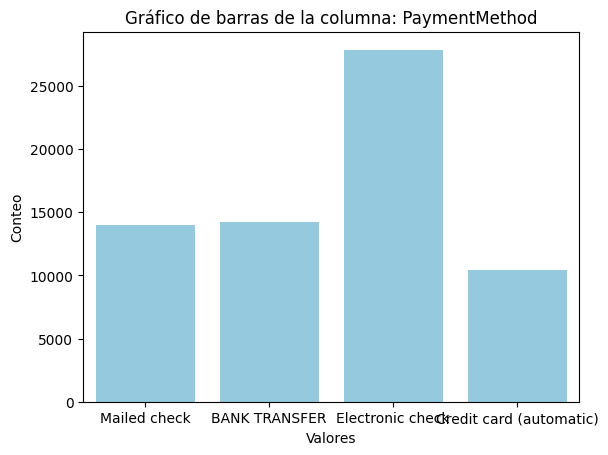

La frecuencia de los valores de esta columna son: Churn
No         37148
Yes        32798
Unknown       54
Name: count, dtype: int64
Y su porcentaje equivale a Churn
No         53.068571
Yes        46.854286
Unknown     0.077143
Name: proportion, dtype: float64%


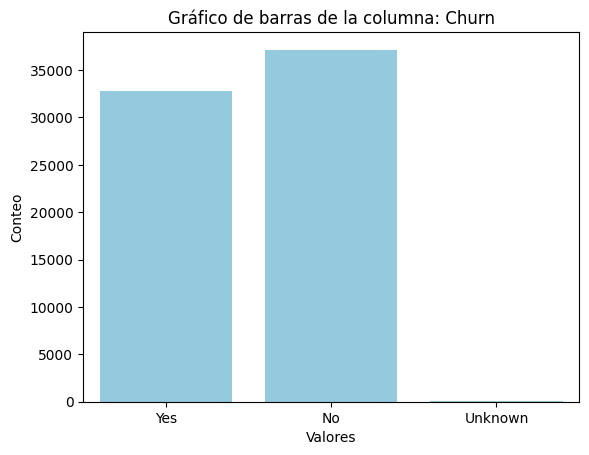

In [15]:
#Análisis univariado de variables categóricas
for col in cat_cols:
  if col == 'customerID':
    continue
  else:
    frecuencia = df[col].value_counts()
    porcentaje = (df[col].value_counts(normalize=True))*100
    print(f'La frecuencia de los valores de esta columna son: {frecuencia}\nY su porcentaje equivale a {porcentaje}%')
    sns.countplot(x=col, data=df, color='skyblue')
    plt.title(f'Gráfico de barras de la columna: {col}')
    plt.xlabel('Valores')
    plt.ylabel('Conteo')
    plt.show()

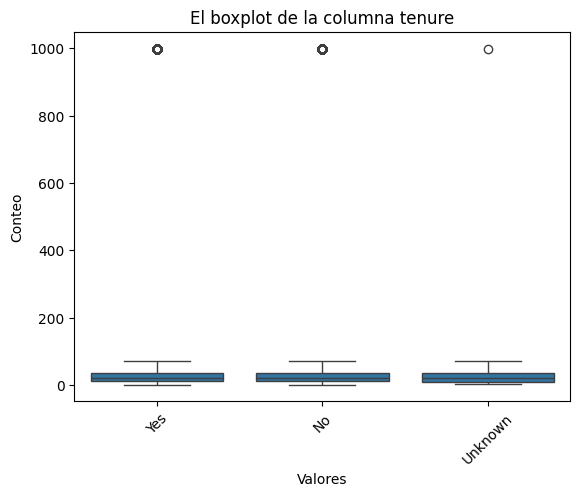

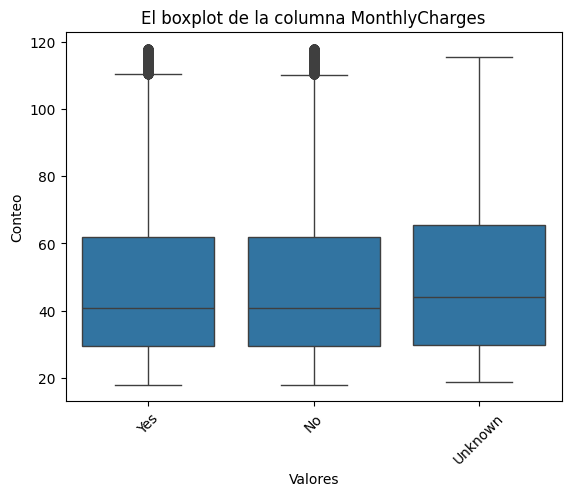

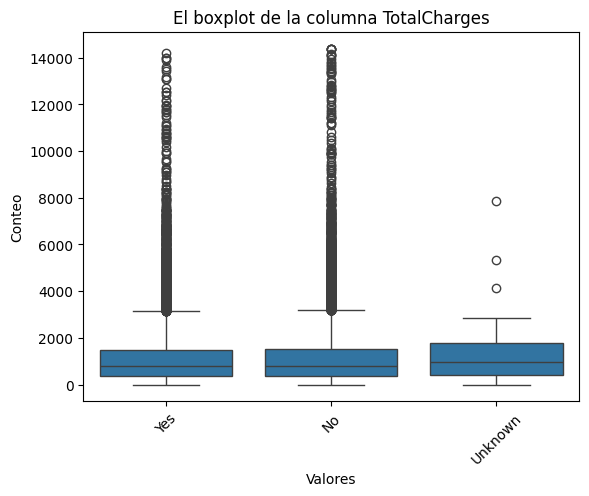

In [16]:
#Análisis bivariado (Variables predictoras vs. Churn)

for col in num_cols:
  sns.boxplot(data= df, y=df[col], x=df['Churn'])
  plt.title(f'El boxplot de la columna {col}')
  plt.xlabel('Valores')
  plt.ylabel('Conteo')
  plt.xticks(rotation=45)
  plt.show()

Las columnas númericas estan muy balanceadas entre sí, no hay un comportamiento que indique que hay alguna relación especifica.

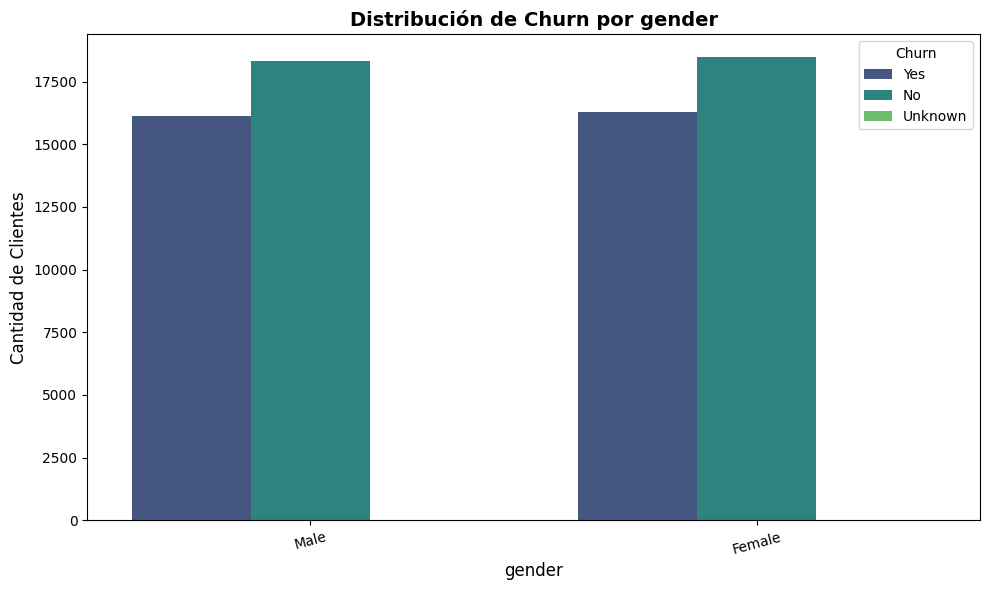

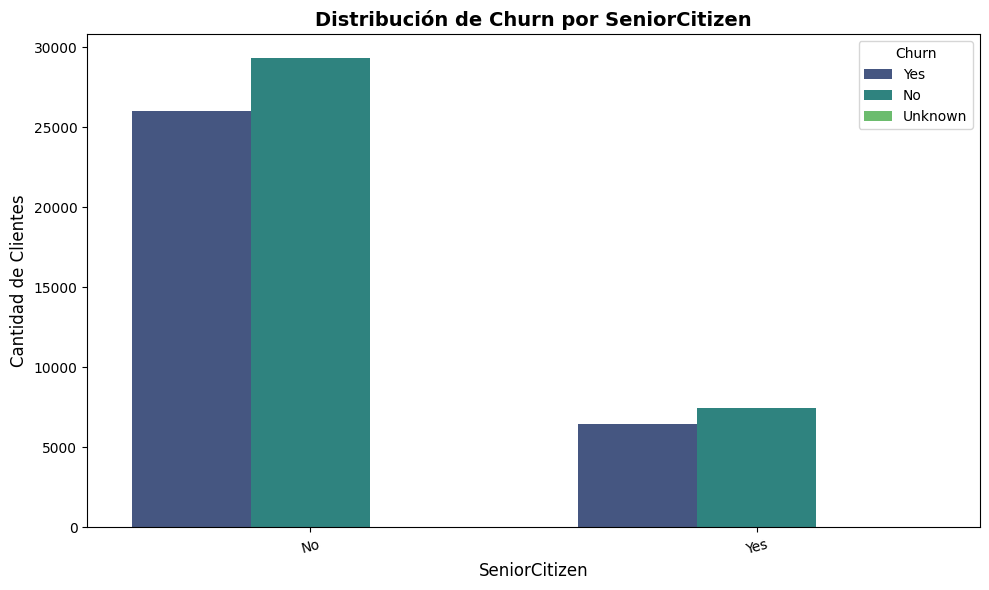

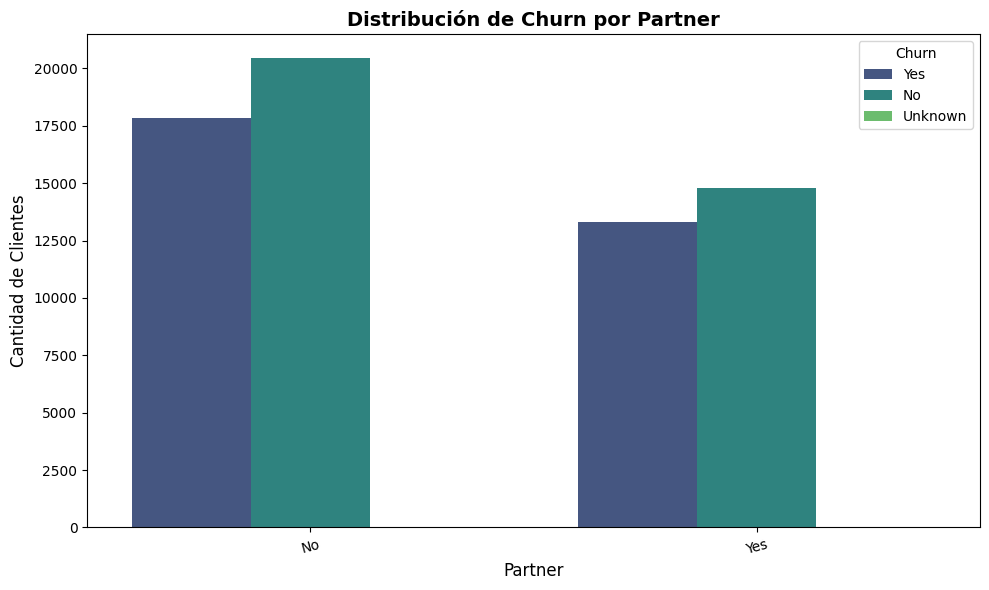

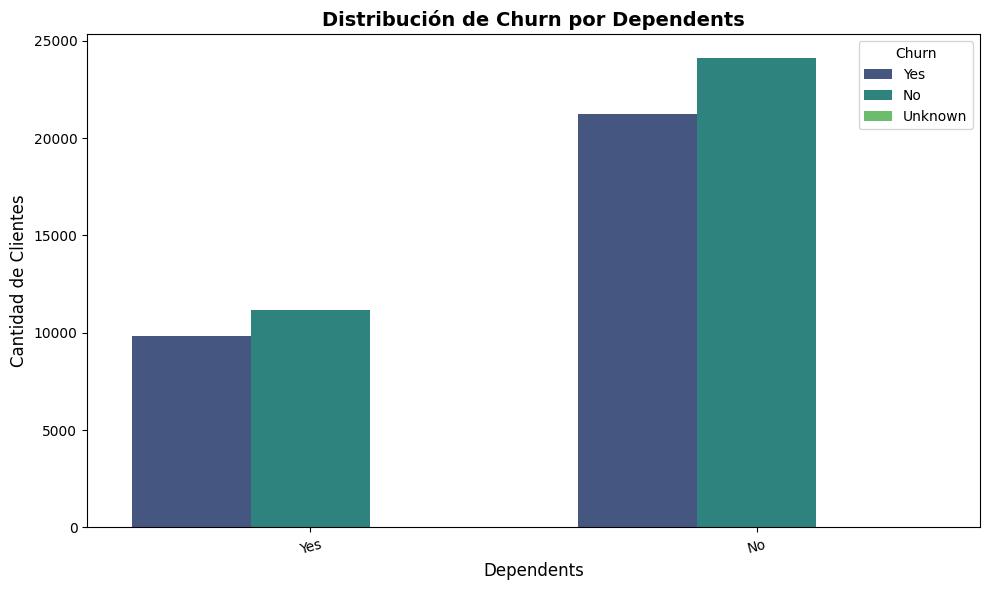

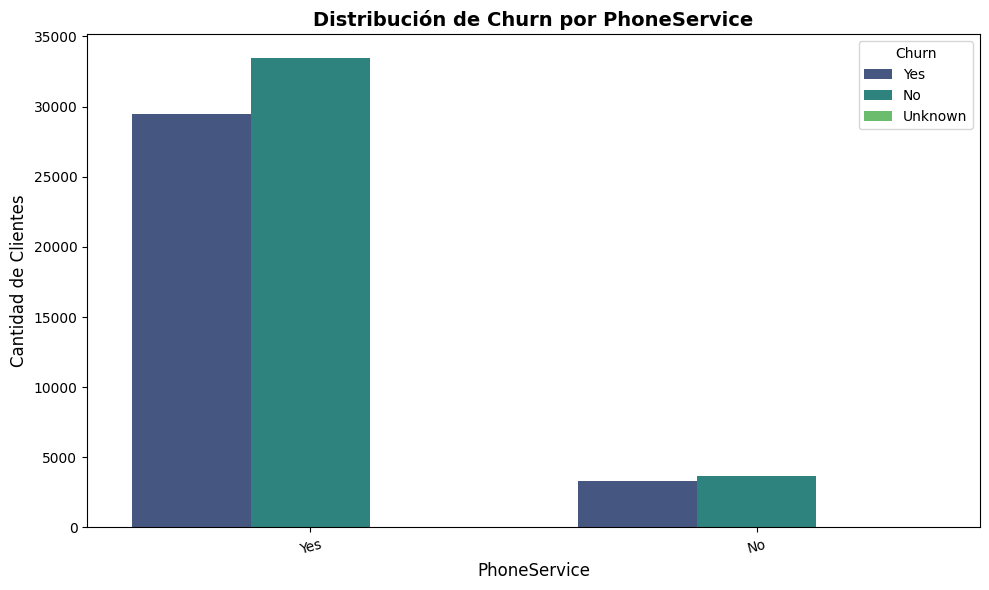

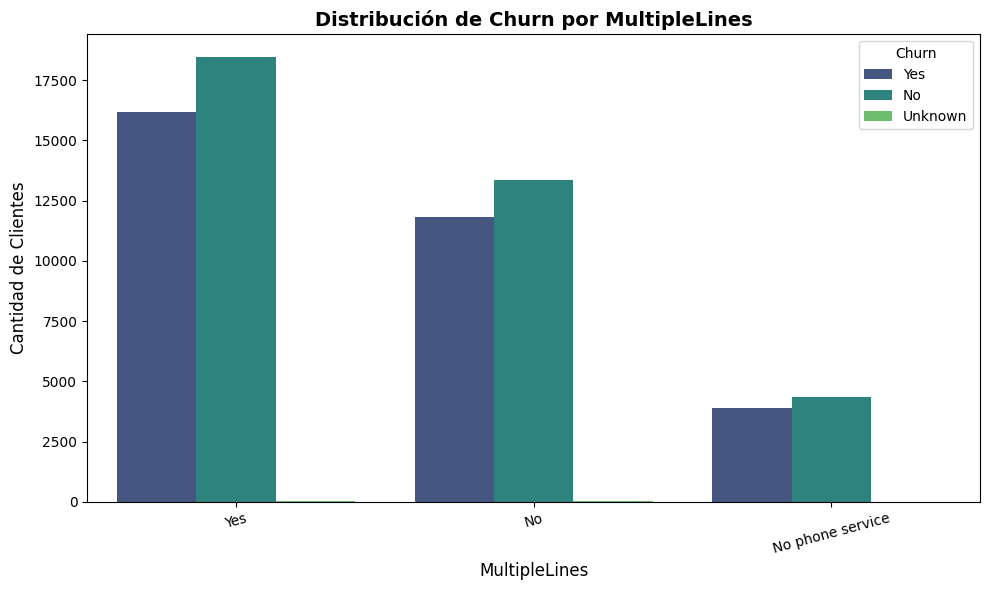

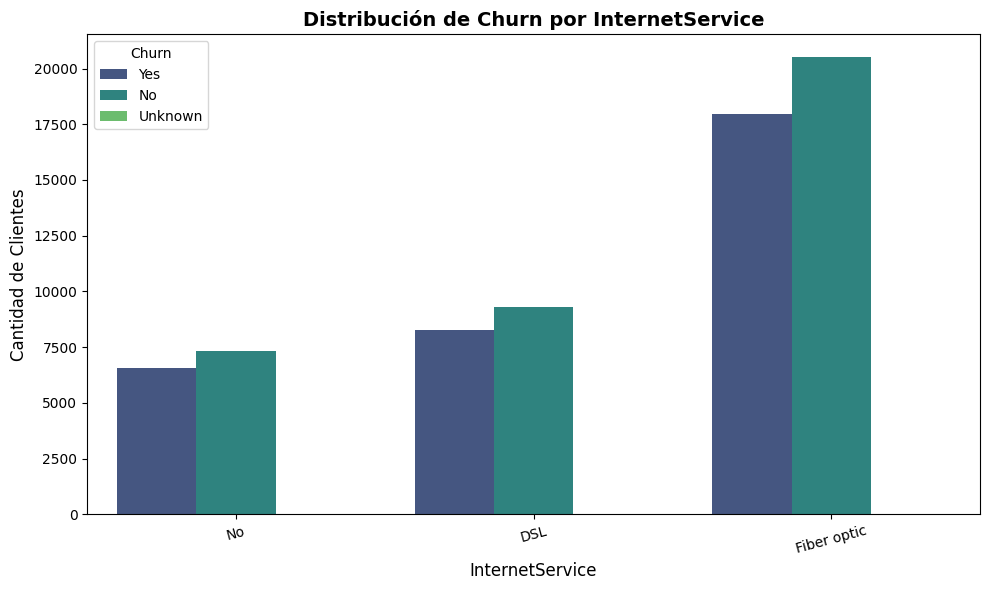

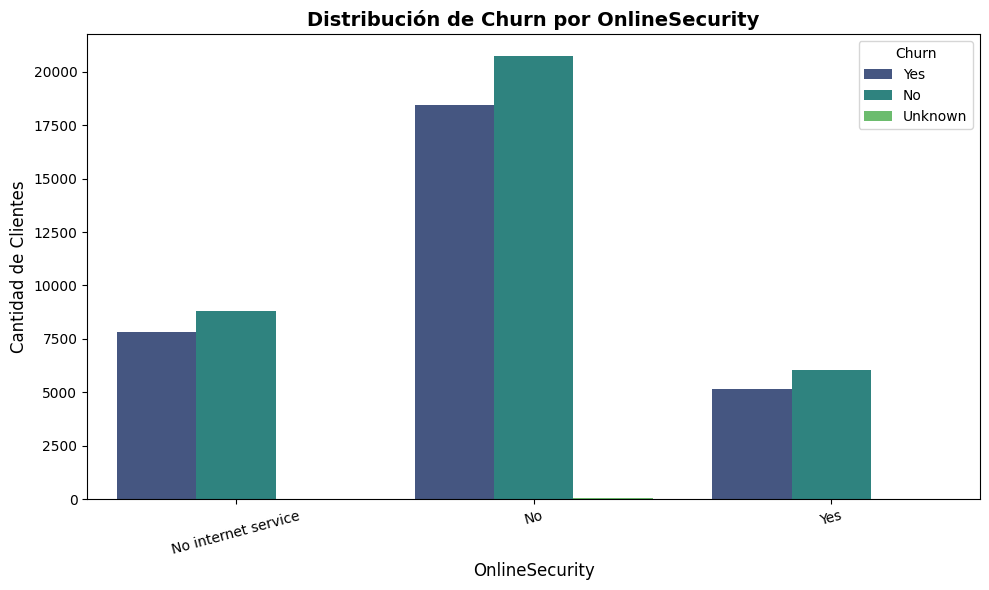

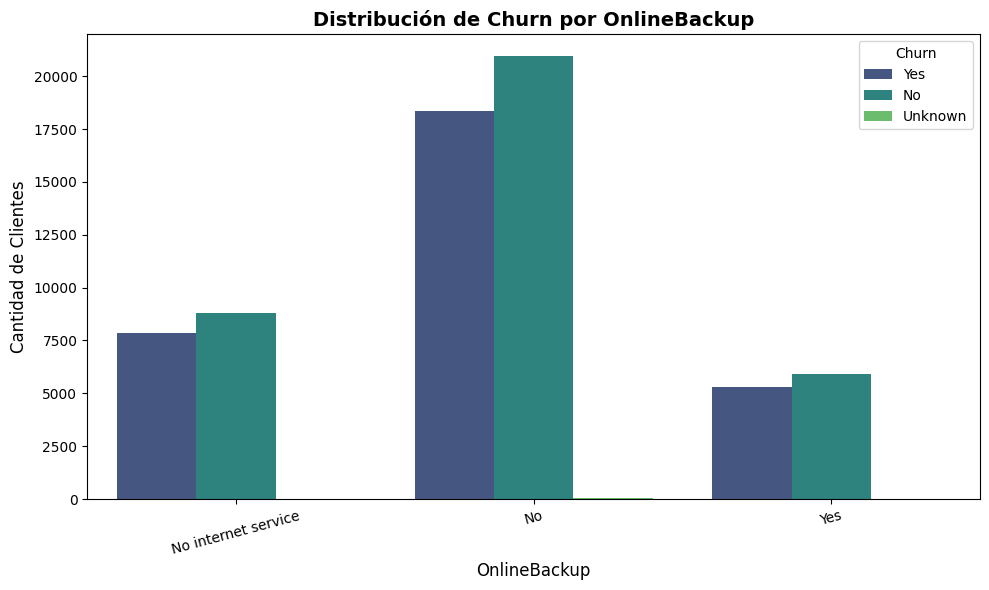

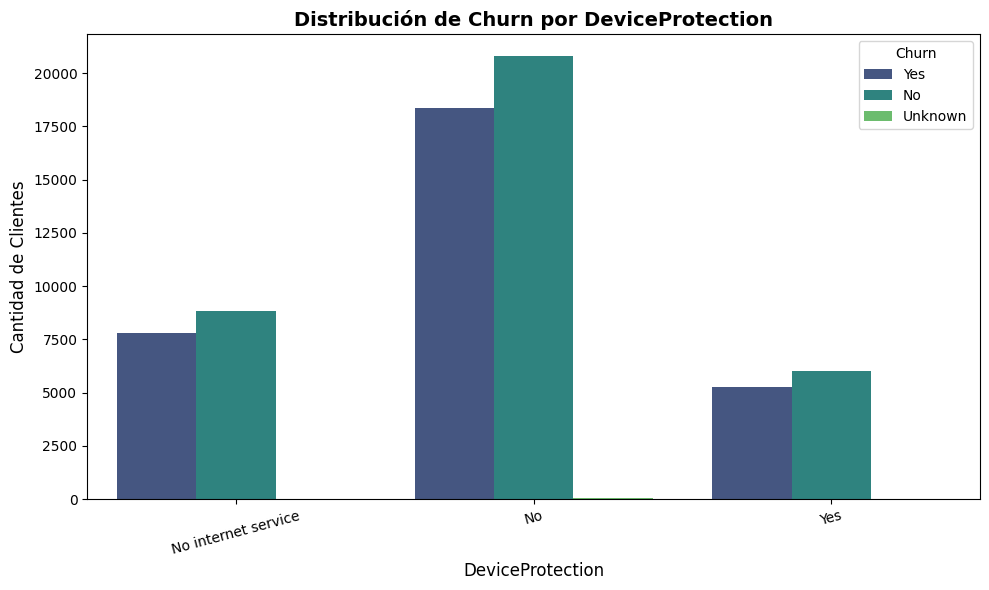

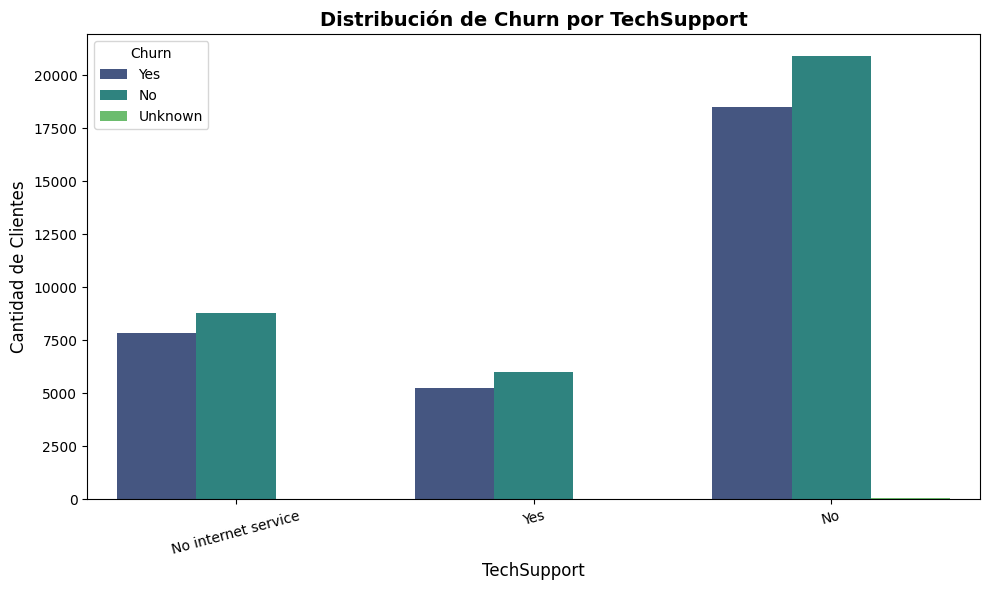

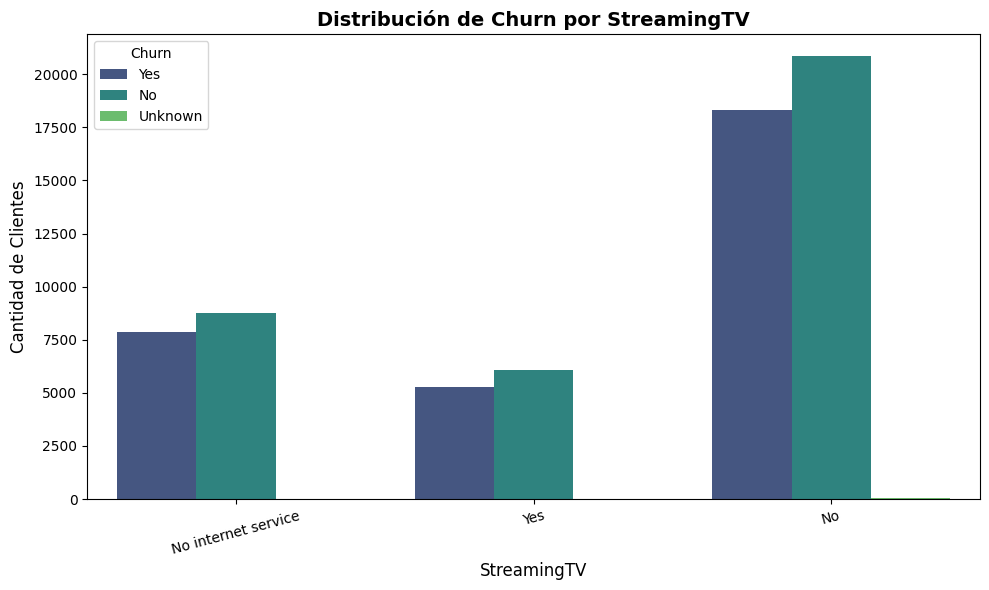

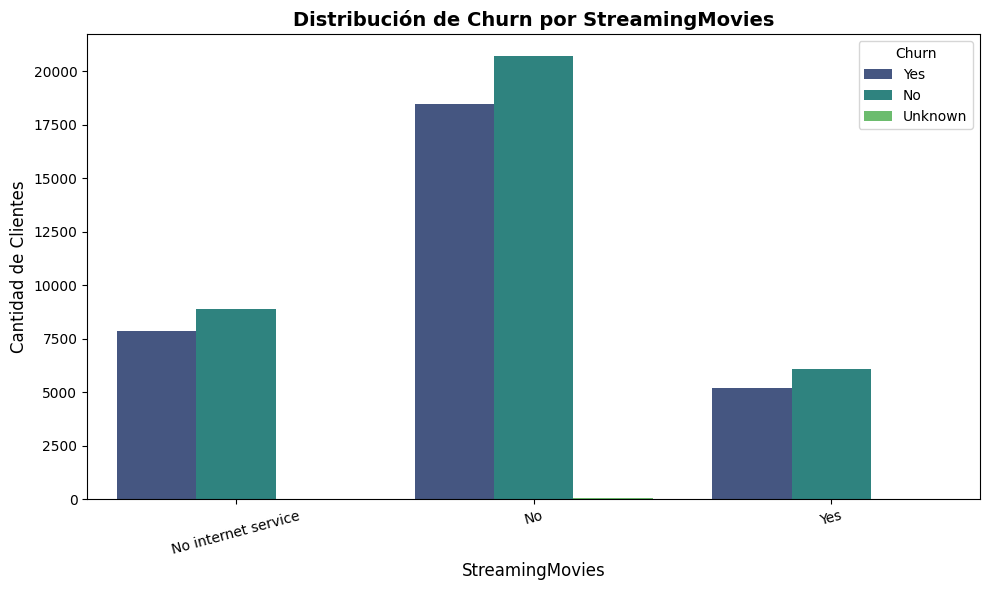

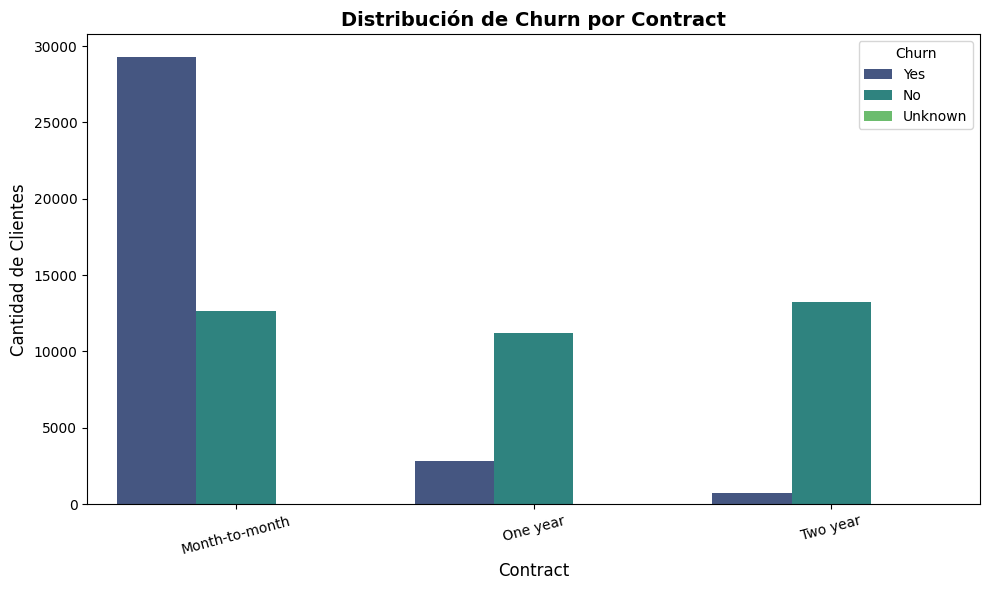

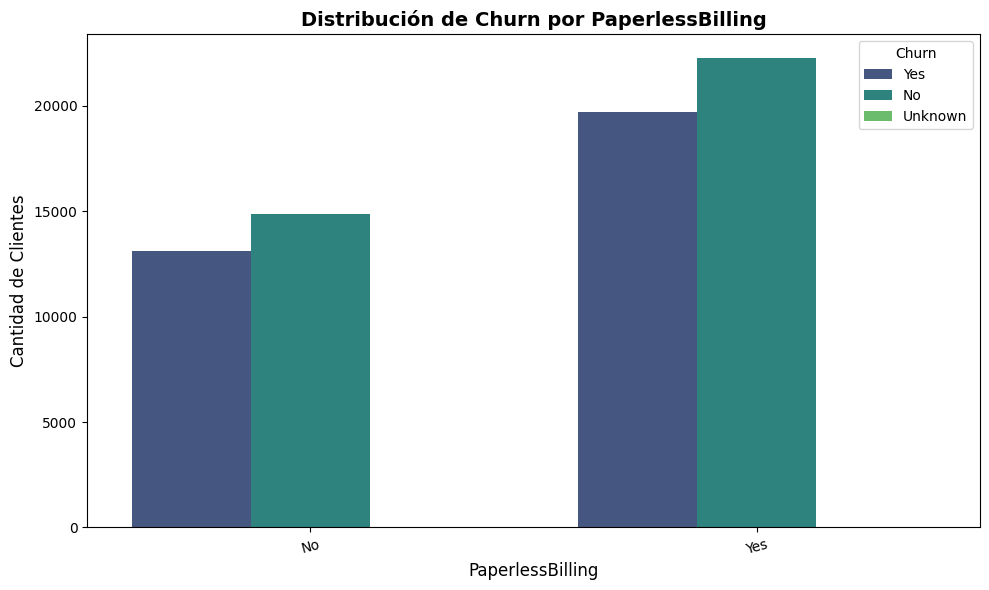

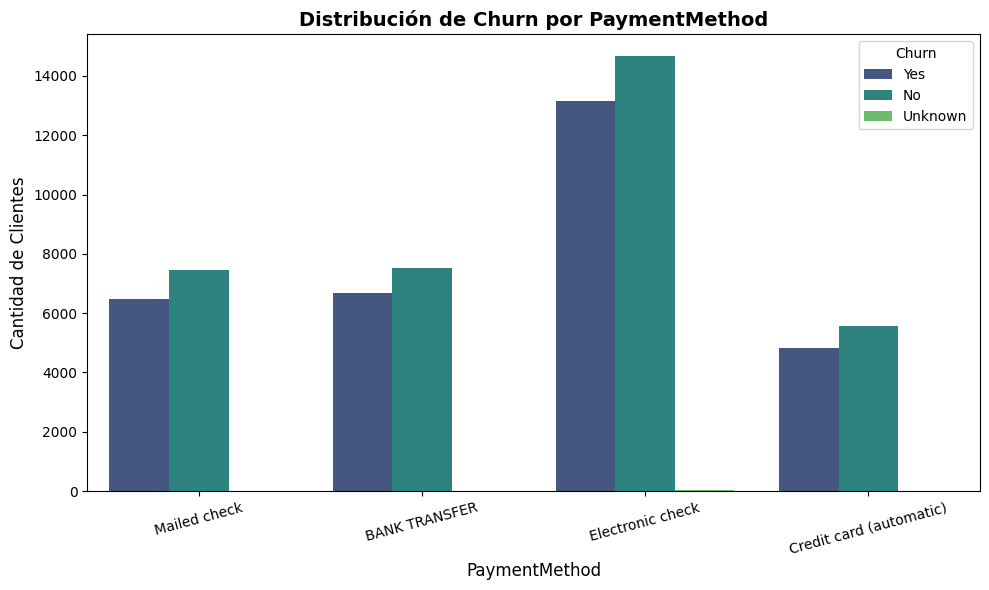

In [17]:
for col in cat_cols:
  if col =='customerID' or col=='Churn':
    continue
  else:
    plt.figure(figsize=(10,6))
    sns.countplot(data=df, x=df[col], hue=df['Churn'], palette='viridis')
    plt.title(f'Distribución de Churn por {col}', fontsize=14, fontweight='bold')
    plt.xlabel(f'{col}', fontsize=12)
    plt.ylabel('Cantidad de Clientes', fontsize=12)
    plt.xticks(rotation=15) # Rota las etiquetas si los nombres son largos

    plt.tight_layout()
    plt.show()



A diferencia de las variables númericas en las categoricas sí hay una diferencia en la conversión basado en ciertos valores por cada columna.

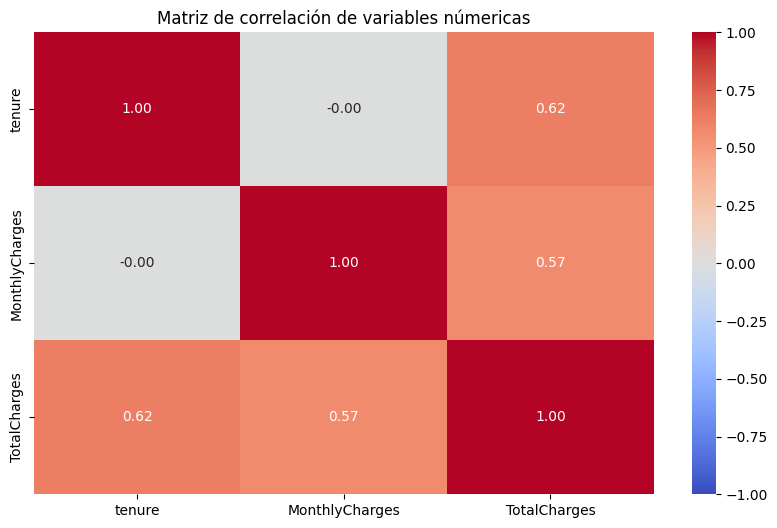

In [18]:
#Matriz de correlación
numeric_df = df[num_cols]
#matriz
corr_matrix = numeric_df.corr()
#Gráfica
plt.figure(figsize=(10,6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Matriz de correlación de variables númericas')
plt.show()

# Hallazgo
No hay una relación realmente fuerte entre estas variables que genere posibles problemas de multicolinealidad.

In [19]:
#Imputar valores nulos en variables númericas
# 1. Eliminar registros con 'Unknown' o nulos en la variable objetivo
df = df[df['Churn'].isin(['No', 'Yes'])].copy()

# 2. Imputación de TotalCharges basada en tenure y MonthlyCharges
mask_total_null = df['TotalCharges'].isnull()
df.loc[mask_total_null & (df['tenure'] == 0), 'TotalCharges'] = 0.0
df.loc[mask_total_null & (df['tenure'] > 0), 'TotalCharges'] = (
    df['tenure'] * df['MonthlyCharges']
)

# 3. Imputación de MonthlyCharges si tenure > 0
mask_monthly_null = df['MonthlyCharges'].isnull() & (df['tenure'] > 0)
df.loc[mask_monthly_null, 'MonthlyCharges'] = (
    df['TotalCharges'] / df['tenure']
)

# 4. Imputación de tenure si es necesario
mask_tenure_null = (
    df['tenure'].isnull()
    & (df['MonthlyCharges'].notnull())
    & (df['MonthlyCharges'] > 0)
)
df.loc[mask_tenure_null, 'tenure'] = (
    df['TotalCharges'] / df['MonthlyCharges']
).round()

for col in cat_cols:
  if col =='customerID':
    continue
  else:
    moda =df[col].mode()[0]
    df[col] = df[col].fillna(moda)
for col in num_cols:
  df[col] = df[col].fillna(df[col].median())

print(df.isna().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


# Preprocesamiento

In [20]:
#1. Codificación de variables categóricas (Encoding)
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
# Variables nominales (múltiples categorías sin orden lógico
nominal_cols = [
    'gender',
    'SeniorCitizen',
    'Partner',
    'PhoneService',
    'Dependents',
    'PaperlessBilling',
    'MultipleLines',
    'InternetService',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies',
    'PaymentMethod',
]
df_cod = pd.get_dummies(df,columns=nominal_cols, drop_first=True)
encoder = OrdinalEncoder(categories= [['Month-to-month','One year','Two year']])
df_cod['Contract'] = encoder.fit_transform(df_cod[['Contract']])

In [21]:
# Escalado de variables numéricas (Scaling)
scaler = StandardScaler()
df_cod[num_cols] = scaler.fit_transform(df_cod[num_cols])

In [22]:
# División de datos (Train-Test Split)
from sklearn.model_selection import train_test_split
X = df_cod.drop(columns=['customerID','Churn'])
y = df_cod['Churn']

X_train, x_test, y_train, y_test = train_test_split(X, y,test_size=0.2, random_state=42,stratify=y)

# Entrenamiento de Modelo

In [23]:
### Fase 1: Entrenamiento del Modelo Base (Baseline)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import  accuracy_score, confusion_matrix

modelo_log = LogisticRegression()
modelo_log.fit(X_train, y_train)
y_pred_test_lr = modelo_log.predict(x_test)
y_pred_train_lr = modelo_log.predict(X_train)

### Fase 2: Evaluación y Métricas de Rendimiento
exactitud_test_log= accuracy_score(y_test, y_pred_test_lr)
exactitud_train_log = accuracy_score(y_train, y_pred_train_lr)

print(f'El accuracy score en train es de: {exactitud_train_log*100:.2f}%')
print(f'El accuracy score en test es de: {exactitud_test_log*100:.2f}%')
print(f'La diferencia es de: {(exactitud_train_log- exactitud_test_log)*100:.2f}%')

El accuracy score en train es de: 76.80%
El accuracy score en test es de: 77.21%
La diferencia es de: -0.41%


In [24]:
### Fase 3: Modelos Avanzados y Comparación
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import recall_score, f1_score

model_rf = RandomForestClassifier(random_state=42,n_estimators=50)
model_rf.fit(X_train, y_train)
y_pred_train_rf = model_rf.predict(X_train)
y_pred_test_rf = model_rf.predict(x_test)

### Evaluación de métricas de rendimiento
## Decisión importante

recall_train =recall_score(y_train, y_pred_train_rf, pos_label='Yes')
recall_test = recall_score(y_test, y_pred_test_rf, pos_label='Yes')
f1_train = f1_score(y_train, y_pred_train_rf, pos_label='Yes')
f1_test = f1_score(y_test, y_pred_test_rf, pos_label='Yes')

print(f'El recall score en train es de: {recall_train*100:.2f}%')
print(f'El recall score en test es de: {recall_test*100:.2f}%')
print(f'La diferencia es de: {(recall_train- recall_test)*100:.2f}%')

print(f'El f1_score en train es de: {f1_train*100:.2f}%')
print(f'El f1_score en test es de: {f1_test*100:.2f}%')
print(f'La diferencia es de: {(f1_train - f1_test)*100:.2f}%')


El recall score en train es de: 99.94%
El recall score en test es de: 82.99%
La diferencia es de: 16.96%
El f1_score en train es de: 99.97%
El f1_score en test es de: 75.97%
La diferencia es de: 24.00%


# Interpretación primeros resultados

En el caso de la Regresión Logística, los resultados de accuracy fueron estables entre entrenamiento y prueba con una diferencia mínima, pero su capacidad de interpretación y desempeño general se mantuvieron bajos (alrededor del 77%), limitando su utilidad para detectar clientes en riesgo.

Por su parte, el Random Forest Classifier mejoró significativamente el rendimiento general evaluado en Recall y F1-Score. Sin embargo, evidencia un claro sobreajuste (overfitting):

Recall en train: 99.94% vs. test: 82.99% (Brecha de ~17%)

F1-Score en train: 99.97% vs. test: 75.97% (Brecha de 24%)

A pesar de la diferencia, los resultados en el conjunto de prueba superan al modelo base. El modelo logra identificar a más del 82% de los clientes reales que cancelarán el servicio (dejando escapar solo a un ~17%, aproximadamente 1 de cada 6), logrando un balance adecuado mediante el F1-Score.

Son resultados sólidos, pero confirman que es indispensable ajustar los hiperparámetros para reducir el sobreajuste y mejorar la capacidad de generalización del modelo.

In [25]:
### Fase 4: Optimización de Hiperparámetros
from sklearn.model_selection import GridSearchCV

model_rf_h = RandomForestClassifier(random_state=42)

param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [10, 20],
    'min_samples_split': [2,5],
    'min_samples_leaf': [1,2],
    'max_features': ['sqrt']
}

grid_search =  GridSearchCV(
    estimator = model_rf_h,
    param_grid = param_grid,
    cv = 5,
    n_jobs=-1,
    scoring= 'recall',
    verbose=2
)

grid_search.fit(X_train, y_train)
y_pred_train_h = grid_search.predict(X_train)
y_pred_test_h = grid_search.predict(x_test)

### Evaluación de métricas de rendimiento
## Decisión importante

recall_train_h =recall_score(y_train, y_pred_train_h, pos_label='Yes')
recall_test_h = recall_score(y_test, y_pred_test_h, pos_label='Yes')
f1_train_h = f1_score(y_train, y_pred_train_h, pos_label='Yes')
f1_test_h = f1_score(y_test, y_pred_test_h, pos_label='Yes')

print(f'El recall score en train es de: {recall_train_h*100:.2f}%')
print(f'El recall score en test es de: {recall_test_h*100:.2f}%')
print(f'La diferencia es de: {(recall_train_h- recall_test_h)*100:.2f}%')

print(f'El f1_score en train es de: {f1_train_h*100:.2f}%')
print(f'El f1_score en test es de: {f1_test_h*100:.2f}%')
print(f'La diferencia es de: {(f1_train_h - f1_test_h)*100:.2f}%')
print("Mejores hiperparámetros:", grid_search.best_params_)


Fitting 5 folds for each of 16 candidates, totalling 80 fits


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:1108: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan]
  warnings.warn(


El recall score en train es de: 89.32%
El recall score en test es de: 89.51%
La diferencia es de: -0.19%
El f1_score en train es de: 78.36%
El f1_score en test es de: 78.64%
La diferencia es de: -0.28%
Mejores hiperparámetros: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 50}


### 5. Interpretación de Resultados e Insights

Tras aplicar la optimización de hiperparámetros mediante `GridSearchCV` enfocado en maximizar el **Recall**, el modelo de **Random Forest** superó los problemas de sobreajuste (*overfitting*) previos, logrando un desempeño robusto, estable y generalizable en el conjunto de prueba.

---

#### 5.1. Evaluación del Rendimiento Optimizado

Los resultados obtenidos con los hiperparámetros óptimos (`max_depth=10`, `n_estimators=50`, `max_features='sqrt'`) muestran las siguientes métricas:

* **Recall en Train:** 89.32%
* **Recall en Test:** 89.51%
* *Diferencia:* -0.19%


* **F1-Score en Train:** 78.36%
* **F1-Score en Test:** 78.64%
* *Diferencia:* -0.28%



#### 5.2. Hallazgos Clave

* **Eliminación del *Overfitting*:** La brecha crítica observada en la versión base (donde el rendimiento superaba el 99% en entrenamiento) se ha corregido por completo. Las métricas en entrenamiento y prueba son prácticamente idénticas, lo que confirma que el modelo ha aprendido patrones reales en lugar de memorizar los datos.
* **Maximización de la Detección de Fugas (*Recall*):** El modelo alcanza un **89.51% de *Recall* en prueba**, lo que significa que es capaz de identificar correctamente a casi **9 de cada 10 clientes** que están en riesgo real de abandonar el servicio. Esto minimiza drásticamente los falsos negativos (clientes perdidos por sorpresa).
* **Control del Balance Operativo (*F1-Score*):** Con un **78.64% en prueba**, el *F1-Score* demuestra que el incremento en el *Recall* no se logró a costa de disparar los falsos positivos. Se mantiene una precisión saludable que evita malgastar recursos económicos en campañas masivas de retención dirigidas a clientes que no pensaban irse.

#### 5.3. Impacto e Insights de Negocio

1. **Eficiencia en la Retención:** Al detectar cerca del 90% de las cancelaciones antes de que ocurran, el departamento de operaciones puede enfocar sus esfuerzos de fidelización (descuentos, atención personalizada, mejoras de servicio) directamente sobre el segmento de alto riesgo.
2. **Mitigación de Costos de Error:** En este sector, el costo de perder un cliente supera con creces el costo de una falsa alarma. Priorizar el *Recall* alinea la precisión técnica del modelo con la estrategia financiera de la empresa.
3. **Estabilidad Operativa:** Gracias a la restricción de la profundidad (`max_depth: 10`) y al uso de árboles independientes (`n_estimators: 50`), el modelo resultante es liviano, rápido en inferencia y confiable para integrarse en flujos de datos automatizados (por ejemplo, evaluaciones mensuales del estado de los usuarios).

                          Variable  Importancia
1                         Contract     0.891316
2                   MonthlyCharges     0.022957
3                     TotalCharges     0.021606
0                           tenure     0.014764
9             PaperlessBilling_Yes     0.002921
4                      gender_Male     0.002809
8                   Dependents_Yes     0.002521
27  PaymentMethod_Electronic check     0.002458
11               MultipleLines_Yes     0.002440
6                      Partner_Yes     0.002413


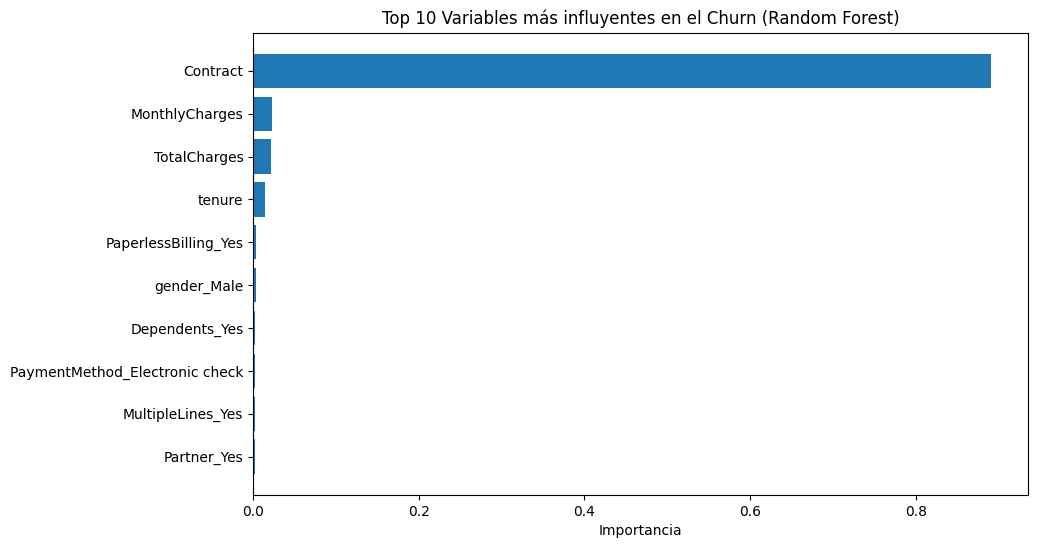

In [26]:
# 1. Obtener el mejor modelo entrenado del GridSearchCV
best_rf = grid_search.best_estimator_

# 2. Extraer las importancias y asociarlas con los nombres de las columnas
feature_importances = best_rf.feature_importances_
feature_names = X_train.columns  # Asumiendo que X_train es un DataFrame de pandas

# 3. Crear un DataFrame para ordenar los resultados de mayor a menor
df_importances = pd.DataFrame({
    'Variable': feature_names,
    'Importancia': feature_importances
}).sort_values(by='Importancia', ascending=False)

print(df_importances.head(10)) # Muestra las 10 variables más influentes

# 4. Opcional: Gráfica rápida
plt.figure(figsize=(10, 6))
plt.barh(df_importances['Variable'].head(10)[::-1], df_importances['Importancia'].head(10)[::-1])
plt.xlabel('Importancia')
plt.title('Top 10 Variables más influyentes en el Churn (Random Forest)')
plt.show()